# DFT Oxidation State Assignment

## Histogram of Magnetic Moments

Saved: ../data/figures/magmom_hist/doubleTM_magmom_abs_hist_2x3.pdf


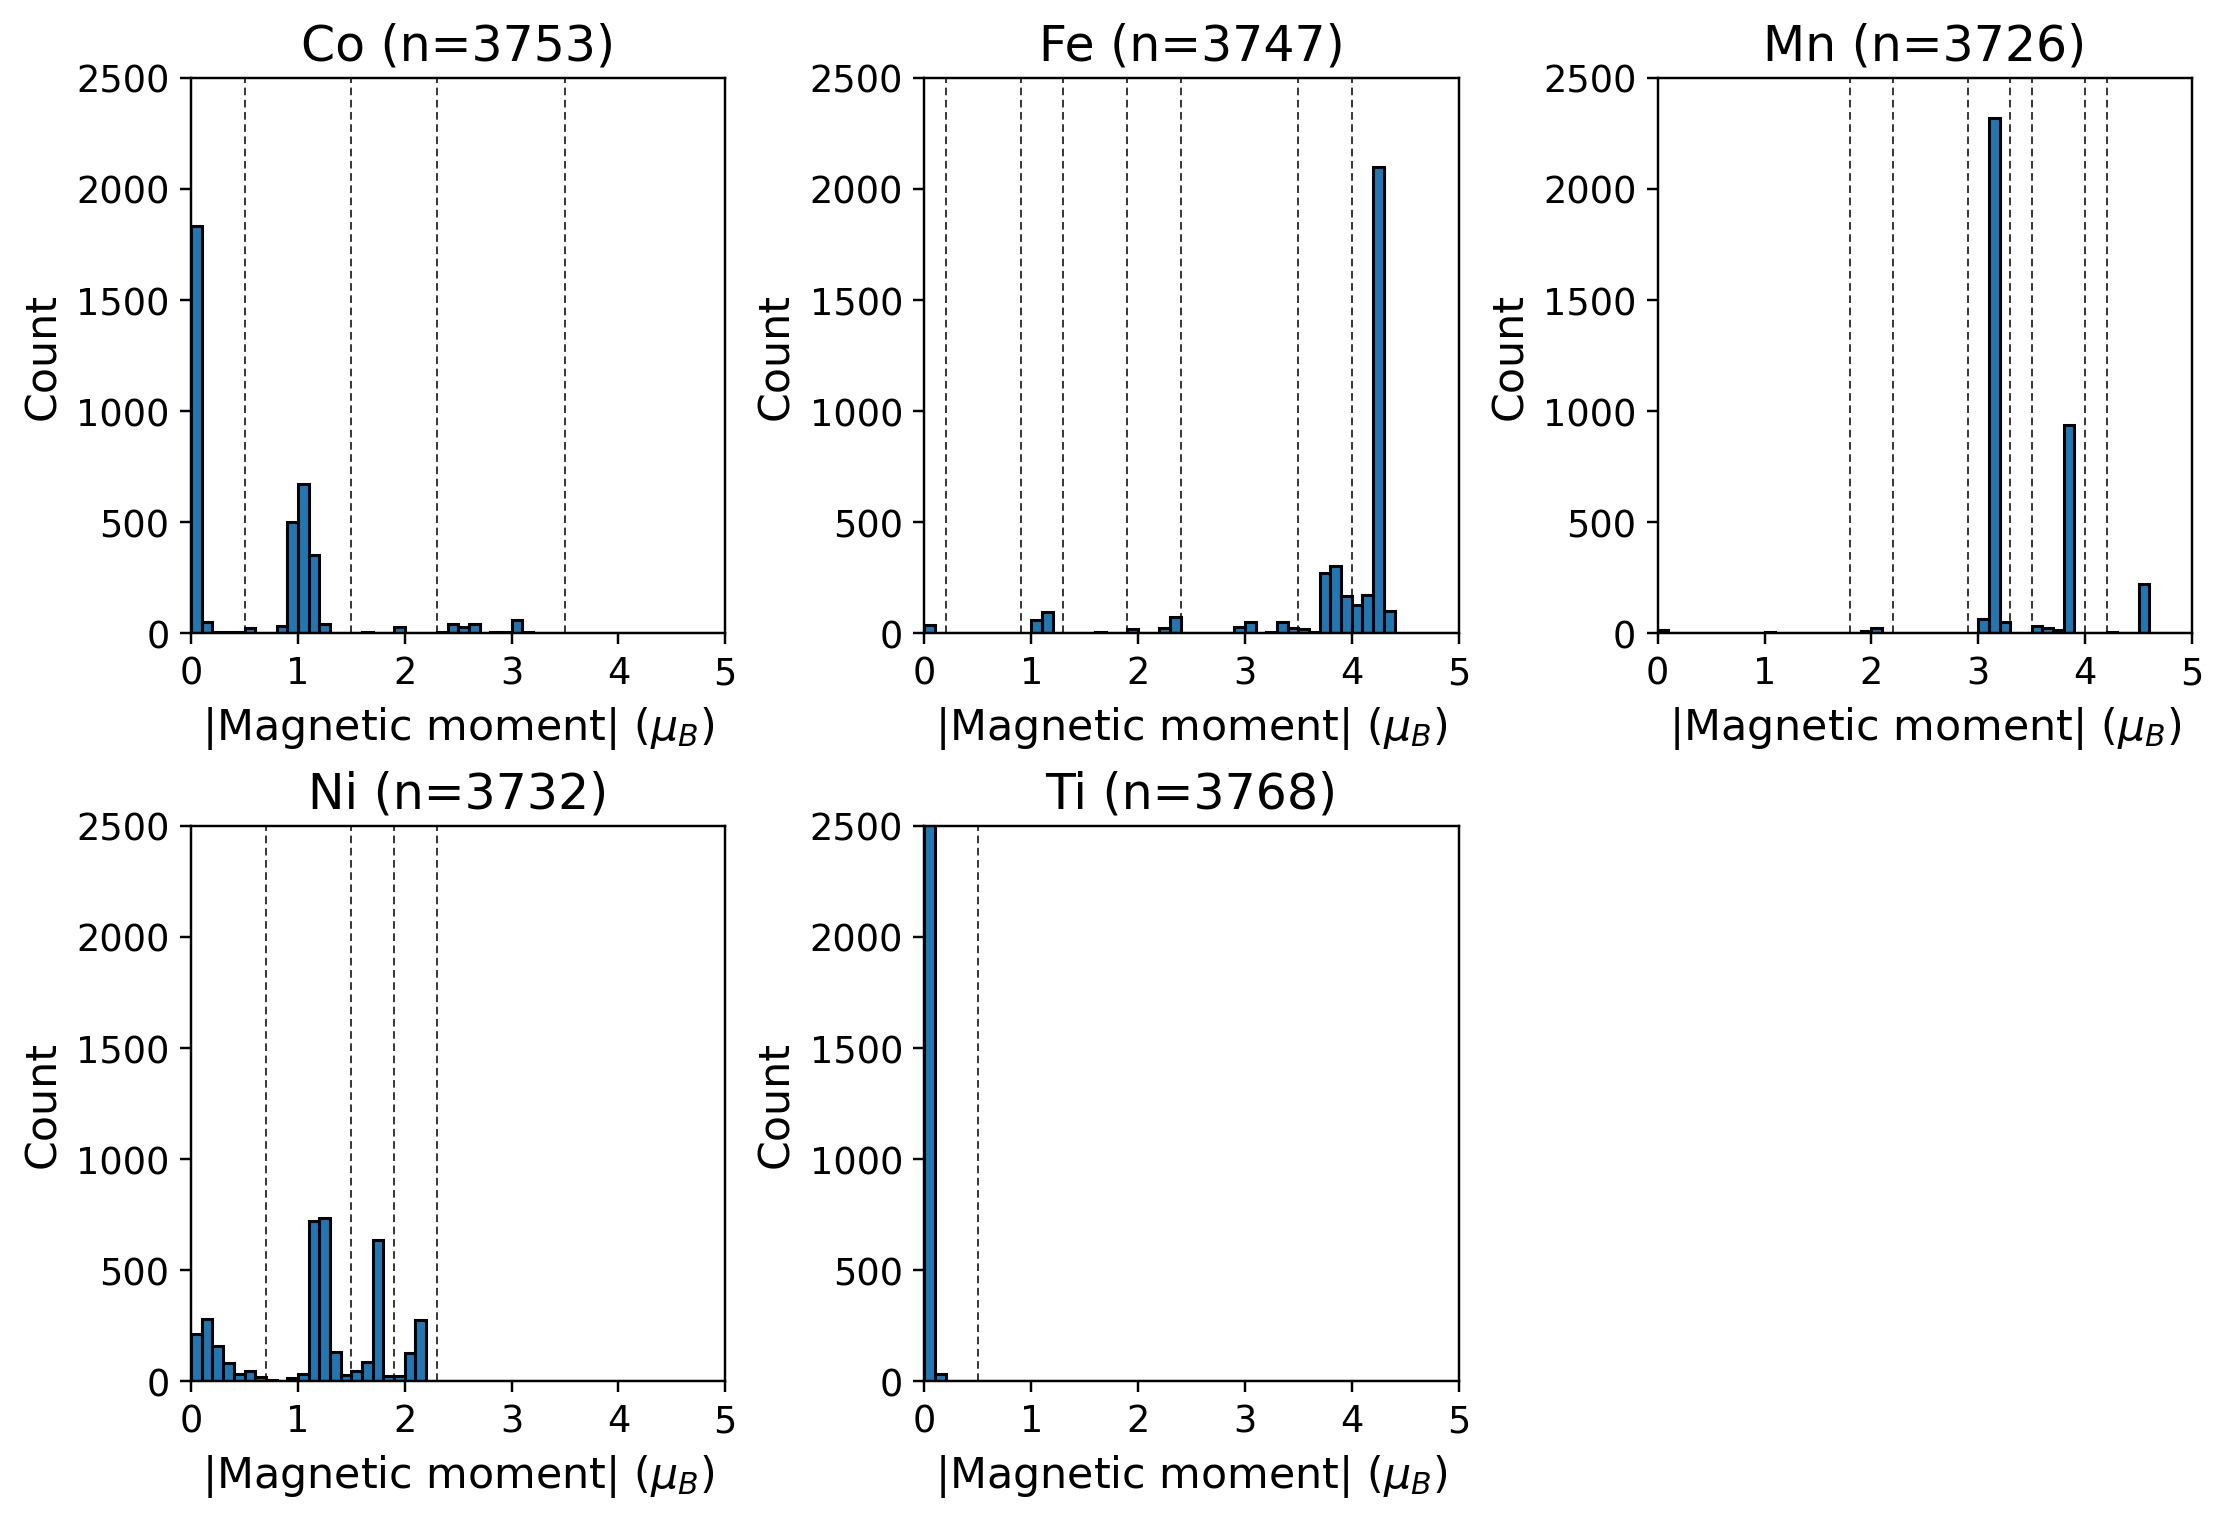

In [1]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('../data/doubleTM_magmom.csv')
save_dir = Path('../data/figures/magmom_hist')
save_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(csv_path)

tm_vals = {}
for raw in df['tm_magmom_dict'].dropna():
    d = ast.literal_eval(raw)
    for tm, arr in d.items():
        tm_vals.setdefault(tm, []).extend(abs(float(x)) for x in arr)

tms = sorted(tm_vals.keys())
bins = np.arange(0, 5.0 + 0.1, 0.1)

fig, axes = plt.subplots(2, 3, figsize=(10, 6.8), dpi=220, constrained_layout=True)
axes = axes.flatten()

for i, tm in enumerate(tms):
    ax = axes[i]
    data = tm_vals[tm]
    ax.hist(data, bins=bins, edgecolor='black')
    if tm == 'Ti':
        ax.axvline(0.5, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
    if tm == 'Ni':
        ax.axvline(0.7, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(1.5, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(1.9, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(2.3, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
    if tm == 'Mn':
        ax.axvline(1.8, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(2.2, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(2.9, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(3.3, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(3.5, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(4.0, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(4.2, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
    if tm == 'Fe':
        ax.axvline(0.2, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(0.9, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(1.3, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(1.9, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(2.4, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(3.5, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(4.0, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
    if tm == 'Co':
        ax.axvline(0.5, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(1.5, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(2.3, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))
        ax.axvline(3.5, color='black', linestyle='--', linewidth=0.5, dashes=(5, 3))

    ax.set_title(f'{tm} (n={len(data)})', fontsize=16)
    ax.set_xlabel('|Magnetic moment| ($\mu_{B}$)', fontsize=14)
    ax.set_ylabel('Count', fontsize=14)
    ax.tick_params(axis='both', labelsize=12)
    ax.set_xlim(0, 5)
    ax.set_xticks([0, 1, 2, 3, 4, 5])
    ax.set_ylim(0, 2500)

for j in range(len(tms), len(axes)):
    axes[j].axis('off')

out_path = save_dir / 'doubleTM_magmom_abs_hist_2x3.pdf'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print(f'Saved: {out_path.resolve()}')
plt.show()


In [2]:
from pathlib import Path
import ast
import re
import numpy as np
import pandas as pd


# =========================
# 1) Load data
# =========================
dft_path = Path('../data/doubleTM_dft_tighter.csv')
magmom_candidates = [
    Path('../data/doubleTM_mgamom.csv'),  # user-requested filename
    Path('../data/doubleTM_magmom.csv'),  # fallback
]
magmom_path = next((p for p in magmom_candidates if p.exists()), None)
if magmom_path is None:
    raise FileNotFoundError('Neither ../data/doubleTM_mgamom.csv nor ../data/doubleTM_magmom.csv exists.')

print(f'Using DFT file   : {dft_path}')
print(f'Using magmom file: {magmom_path}')

df = pd.read_csv(dft_path)

mask = pd.Series(True, index=df.index)
if 'status' in df.columns:
    mask &= df['status'].astype(str).eq('OK')
if 'converged' in df.columns:
    c = df['converged']
    if c.dtype == object:
        c = c.astype(str).str.lower().eq('true')
    mask &= c
if 'n_custodian_errors' in df.columns:
    mask &= pd.to_numeric(df['n_custodian_errors'], errors='coerce').fillna(0).eq(0)

df = df[mask].copy()
for col in ['natoms', 'energy_eV', 'energy_per_atom_eV']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')


# =========================
# 2) Formula parsing helpers
# =========================
def expand_parentheses(formula):
    text = str(formula)
    group_pat = re.compile(r'\(([^()]+)\)(\d*)')
    atom_pat = re.compile(r'([A-Z][a-z]?)(\d*)')

    while True:
        m = group_pat.search(text)
        if m is None:
            break
        inner = m.group(1)
        mult = int(m.group(2) or '1')
        expanded = []
        for el, n in atom_pat.findall(inner):
            cnt = int(n or '1') * mult
            expanded.append(f"{el}{cnt if cnt != 1 else ''}")
        text = text[:m.start()] + ''.join(expanded) + text[m.end():]

    return text


def parse_formula_counts(formula):
    if pd.isna(formula):
        return None
    text = str(formula).replace(' ', '')
    if not text:
        return None
    text = expand_parentheses(text)

    tokens = re.findall(r'([A-Z][a-z]?)(\d*)', text)
    if not tokens:
        return None

    counts = {}
    for el, n in tokens:
        counts[el] = counts.get(el, 0) + int(n or '1')
    return counts


def xna_from_row(row):
    counts = row['formula_counts']
    if not isinstance(counts, dict):
        return np.nan
    try:
        tm1, tm2 = str(row['tm_pair']).split('_')
    except Exception:
        return np.nan

    n_tm = counts.get(tm1, 0) + counts.get(tm2, 0)
    if n_tm <= 0:
        return np.nan
    return counts.get('Na', 0) / n_tm


def energy_per_tmo2(row):
    counts = row['formula_counts']
    if not isinstance(counts, dict):
        return np.nan

    try:
        tm1, tm2 = str(row['tm_pair']).split('_')
    except Exception:
        return np.nan

    natoms = row.get('natoms', np.nan)
    if not np.isfinite(natoms) or natoms <= 0:
        return np.nan

    n_formula = sum(counts.values())
    if n_formula <= 0:
        return np.nan

    n_tm_formula = counts.get(tm1, 0) + counts.get(tm2, 0)
    if n_tm_formula <= 0:
        return np.nan

    scale = natoms / n_formula
    n_tmo2 = n_tm_formula * scale
    if n_tmo2 <= 0:
        return np.nan

    e_tot = row.get('energy_eV', np.nan)
    if np.isfinite(e_tot):
        e_total = float(e_tot)
    else:
        epa = row.get('energy_per_atom_eV', np.nan)
        if not np.isfinite(epa):
            return np.nan
        e_total = float(epa) * float(natoms)

    return e_total / n_tmo2


# =========================
# 3) Build convex-hull stable points (elec_0 + elec_1 included)
# =========================
def lower_hull_indices(xs, ys):
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    if xs.size == 0:
        return []

    # Keep one minimum-energy point per x
    uniq_idx = []
    for x in np.sort(np.unique(xs)):
        idx = np.where(np.isclose(xs, x))[0]
        pick = idx[np.argmin(ys[idx])]
        uniq_idx.append(pick)

    if len(uniq_idx) <= 2:
        return sorted(uniq_idx, key=lambda i: xs[i])

    ordered = sorted(uniq_idx, key=lambda i: (xs[i], ys[i]))
    lower = []
    for idx in ordered:
        while len(lower) >= 2:
            i = lower[-2]
            j = lower[-1]
            cross = (xs[j] - xs[i]) * (ys[idx] - ys[i]) - (ys[j] - ys[i]) * (xs[idx] - xs[i])
            if cross <= 0:
                lower.pop()
            else:
                break
        lower.append(idx)
    return lower


df['formula_counts'] = df['formula'].apply(parse_formula_counts)
df['xNa'] = df.apply(xna_from_row, axis=1)
df['E_TMO2_eV'] = df.apply(energy_per_tmo2, axis=1)
df['elec'] = df['elec'].fillna('elec_unknown').astype(str)
df = df.dropna(subset=['xNa', 'E_TMO2_eV']).copy()

point_cols = ['tm_pair', 'phase', 'ordering', 'elec', 'xNa']
df_points = (
    df.groupby(point_cols, as_index=False)
      .agg({'E_TMO2_eV': 'mean', 'formula': 'first', 'formula_counts': 'first'})
)

print()
print('Candidate points by elec used for hull search:')
print(df_points.groupby('elec').size().to_string())

stable_tables = []
for tm_pair in sorted(df_points['tm_pair'].dropna().unique()):
    pair_df = df_points[df_points['tm_pair'] == tm_pair].copy().reset_index(drop=True)
    if len(pair_df) < 2:
        continue

    hull_idx = lower_hull_indices(pair_df['xNa'].to_numpy(), pair_df['E_TMO2_eV'].to_numpy())
    if len(hull_idx) < 2:
        continue

    stable = pair_df.iloc[hull_idx].sort_values('xNa').reset_index(drop=True)
    stable_tables.append(stable)

    print()
    print(f'=== {tm_pair}: convex-hull stable points ===')
    print(stable[['xNa', 'phase', 'ordering', 'elec']].to_string(index=False))

if not stable_tables:
    raise RuntimeError('No stable convex-hull points found.')

stable_df = pd.concat(stable_tables, ignore_index=True)


# =========================
# 4) Magmom lookup
# =========================
mag_df = pd.read_csv(magmom_path)
if 'tm_ordering' in mag_df.columns:
    mag_df['elec_key'] = mag_df['tm_ordering'].astype(str)
elif 'elec' in mag_df.columns:
    mag_df['elec_key'] = mag_df['elec'].astype(str)
else:
    raise KeyError('Magmom file needs tm_ordering or elec column.')

mm_lookup = {
    (str(r['phase']), str(r['ordering']), str(r['tm_pair']), str(r['elec_key'])): r['tm_magmom_dict']
    for _, r in mag_df.iterrows()
}


def magmom_list_abs(raw_dict_str, tm):
    if pd.isna(raw_dict_str):
        return []
    try:
        parsed = ast.literal_eval(str(raw_dict_str))
    except Exception:
        return []
    if not isinstance(parsed, dict) or tm not in parsed:
        return []

    out = []
    for v in parsed[tm]:
        try:
            out.append(abs(float(v)))
        except Exception:
            pass
    return out


# =========================
# 5) Atom-wise oxidation rules
# =========================
def oxidation_candidates(tm, m):
    if not np.isfinite(m):
        return []
    x = float(m)

    if tm == 'Ti':
        return [4] if x < 0.5 else []

    if tm == 'Ni':
        if x < 0.7:
            return [4]
        if 0.7 < x < 1.5:
            return [3]
        if 1.5 < x < 1.9:
            return [2]
        if 1.9 < x < 2.3:
            return [3]
        return []

    if tm == 'Co':
        if x < 0.5:
            return [3]
        if 0.5 < x < 1.5:
            return [2, 4]  # ambiguous; solve via neutrality
        if 2.3 < x < 3.5:
            return [2]
        return []

    if tm == 'Fe':
        if x < 0.2:
            return [2]
        if 0.9 < x < 1.3:
            return [3]
        if 1.9 < x < 2.4:
            return [4]
        if 3.5 < x < 4.1:
            return [2, 4]  # ambiguous; solve via neutrality
        if 4.1 < x:
            return [3]
        return []

    if tm == 'Mn':
        if 1.8 < x < 2.2:
            return [3]
        if 2.9 < x < 3.3:
            return [4]
        if 3.5 < x < 4.0:
            return [3]
        if 4.2 < x:
            return [2]
        return []

    return []


def build_best_options_by_sum(candidates_per_atom):
    """
    For one TM species, return best atom-wise oxidation assignment for each reachable sum.
    """
    # states at each step: dict[(sum, mask)] = (prev_key, chosen_ox)
    layers = []
    states = {(0, 0): (None, None)}

    for cand in candidates_per_atom:
        nxt = {}
        for (s_prev, mask_prev) in states.keys():
            for ox in cand:
                ox = int(ox)
                key = (s_prev + ox, mask_prev | (1 << ox))
                if key not in nxt:
                    nxt[key] = ((s_prev, mask_prev), ox)
        layers.append(nxt)
        states = nxt

    if not layers:
        return {}

    final_states = layers[-1]

    def reconstruct(final_key):
        assign = []
        key = final_key
        for i in range(len(layers) - 1, -1, -1):
            parent, ox = layers[i][key]
            assign.append(int(ox))
            key = parent
        assign.reverse()
        return assign

    # choose best assignment per sum by maximizing oxidation diversity
    best = {}
    for (sum_ox, mask) in final_states.keys():
        diversity = int(mask.bit_count())
        cand_sol = {
            'assignment': reconstruct((sum_ox, mask)),
            'mask': mask,
            'diversity': diversity,
        }
        cur = best.get(sum_ox)
        if cur is None:
            best[sum_ox] = cand_sol
        else:
            if cand_sol['diversity'] > cur['diversity']:
                best[sum_ox] = cand_sol

    return best


def solve_atomwise_pair(tm1, tm2, m1_list, m2_list, counts):
    if not isinstance(counts, dict):
        return None

    c1 = [oxidation_candidates(tm1, m) for m in m1_list]
    c2 = [oxidation_candidates(tm2, m) for m in m2_list]

    if not c1 or not c2:
        return None
    if any(len(c) == 0 for c in c1) or any(len(c) == 0 for c in c2):
        return None

    n1_red = counts.get(tm1, 0)
    n2_red = counts.get(tm2, 0)
    na_red = counts.get('Na', 0)
    o_red = counts.get('O', 0)
    if n1_red <= 0 or n2_red <= 0:
        return None

    # infer supercell multiplier from list lengths
    s1 = len(c1) / n1_red
    s2 = len(c2) / n2_red
    if abs(s1 - s2) > 1e-8:
        return None
    scale = 0.5 * (s1 + s2)

    # charge neutrality: Na(+1) + sum(TM) + O(-2) = 0
    required_tm_sum = (2 * o_red - na_red) * scale
    if abs(required_tm_sum - round(required_tm_sum)) > 1e-8:
        return None
    required_tm_sum = int(round(required_tm_sum))

    # Build best per-species options by sum, then combine to target total sum.
    # Objective: maximize oxidation diversity for each species when multiple neutral solutions exist.
    opt1 = build_best_options_by_sum(c1)
    opt2 = build_best_options_by_sum(c2)

    best_pair = None
    best_score = None
    for s_tm1, sol1 in opt1.items():
        s_tm2 = required_tm_sum - s_tm1
        if s_tm2 not in opt2:
            continue
        sol2 = opt2[s_tm2]

        # score = diversity(tm1) + diversity(tm2)
        score = sol1['diversity'] + sol2['diversity']

        if best_pair is None or score > best_score:
            best_pair = (sol1, sol2)
            best_score = score

    if best_pair is None:
        return None

    ox1 = best_pair[0]['assignment']
    ox2 = best_pair[1]['assignment']

    # final check
    na_super = na_red * scale
    o_super = o_red * scale
    total_charge = na_super + sum(ox1) + sum(ox2) - 2 * o_super
    if abs(total_charge) > 1e-8:
        return None

    return {
        'ox_tm1_list': ox1,
        'ox_tm2_list': ox2,
        'ox_state_tm1_list': [f"{tm1}{int(v)}+" for v in ox1],
        'ox_state_tm2_list': [f"{tm2}{int(v)}+" for v in ox2],
        'charge_neutral': True,
    }


# =========================
# 6) Apply on stable points
# =========================
rows = []
for _, r in stable_df.iterrows():
    tm1, tm2 = str(r['tm_pair']).split('_')
    key = (str(r['phase']), str(r['ordering']), str(r['tm_pair']), str(r['elec']))
    raw_mm = mm_lookup.get(key, np.nan)

    m1_list = magmom_list_abs(raw_mm, tm1)
    m2_list = magmom_list_abs(raw_mm, tm2)

    solved = solve_atomwise_pair(tm1, tm2, m1_list, m2_list, r['formula_counts'])

    if solved is None:
        ox1_list = np.nan
        ox2_list = np.nan
        oxs1_list = np.nan
        oxs2_list = np.nan
        avg_ox_tm1 = np.nan
        avg_ox_tm2 = np.nan
        avg_ox_tm_pair = np.nan
        neutral = False
    else:
        ox1_list = solved['ox_tm1_list']
        ox2_list = solved['ox_tm2_list']
        oxs1_list = solved['ox_state_tm1_list']
        oxs2_list = solved['ox_state_tm2_list']
        avg_ox_tm1 = float(np.mean(ox1_list))
        avg_ox_tm2 = float(np.mean(ox2_list))
        avg_ox_tm_pair = float(np.mean(ox1_list + ox2_list))
        neutral = solved['charge_neutral']

    rows.append({
        'tm_pair': r['tm_pair'],
        'xNa': r['xNa'],
        'phase': r['phase'],
        'ordering': r['ordering'],
        'elec': r['elec'],
        'tm1': tm1,
        'tm2': tm2,
        'magmom_tm1_list': m1_list,
        'magmom_tm2_list': m2_list,
        'ox_tm1_list': ox1_list,
        'ox_tm2_list': ox2_list,
        'ox_state_tm1_list': oxs1_list,
        'ox_state_tm2_list': oxs2_list,
        'avg_ox_tm1': avg_ox_tm1,
        'avg_ox_tm2': avg_ox_tm2,
        'avg_ox_tm_pair': avg_ox_tm_pair,
        'charge_neutral': neutral,
    })

stable_oxi_df = pd.DataFrame(rows).sort_values(
    ['tm_pair', 'xNa', 'phase', 'ordering', 'elec']
).reset_index(drop=True)

print()
print('=== Atom-wise oxidation-state assignment on stable points ===')
print(
    stable_oxi_df[
        [
            'tm_pair', 'xNa', 'phase', 'ordering', 'elec',
            'magmom_tm1_list', 'magmom_tm2_list',
            'ox_state_tm1_list', 'ox_state_tm2_list',
            'avg_ox_tm1', 'avg_ox_tm2',
            'avg_ox_tm_pair', 'charge_neutral'
        ]
    ].to_string(index=False)
)

out_csv = Path('../data/doubleTM_stable_oxi_states.csv')
stable_oxi_df.to_csv(out_csv, index=False)
print()
print(f'Saved: {out_csv.resolve()}')


Using DFT file   : ../data/doubleTM_dft_tighter.csv
Using magmom file: ../data/doubleTM_magmom.csv

Candidate points by elec used for hull search:
elec
elec_0    408
elec_1    405

=== Co_Ni: convex-hull stable points ===
     xNa        phase          ordering   elec
0.000000 O3_orderings          O3_empty elec_1
0.400000 P3_orderings   JLK_zeta2_w_vac elec_0
0.428571 P3_orderings   JLK_zeta3_w_vac elec_0
0.500000 P3_orderings    JLK_zeta_w_vac elec_0
0.666667 P3_orderings   JLK_delta_w_vac elec_1
0.750000 O3_orderings       AJT_o_w_vac elec_1
0.833333 O3_orderings JLK_theta_5_w_vac elec_1
0.888889 O3_orderings       AJT_r_w_vac elec_1
1.000000 P3_orderings           P3_full elec_0

=== Fe_Co: convex-hull stable points ===
     xNa        phase        ordering   elec
0.000000 P3_orderings        P3_empty elec_1
0.250000 O3_orderings     AJT_b_w_vac elec_1
0.333333 O3_orderings            XC_a elec_1
0.428571 P3_orderings JLK_zeta3_w_vac elec_1
0.500000 O3_orderings     AJT_g_w_vac ele

In [3]:
# Voltage curve + oxidation-state overlay (style matched to dft_voltagecurve_doubleTM.ipynb)
import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial import ConvexHull

E_Na_ref = -1.31
F = 96485.33212
PHASE_CHANGE_EDGE_WIDTH = 0.02

experiment_map = {
    "Mn_Fe": {
        "file": "NM2012_NMF.csv",
        "label": "Exp (Yabuuchi et al. Nat. Mater. 2012)",
        "is_capacity": True,
    },
    "Fe_Ni": {
        "file": "JMCA2017_NFN.csv",
        "label": "Exp (Vassilaras et al. JMCA 2017)",
        "is_capacity": False,
    },
    "Co_Ni": {
        "file": "JMCA2017_NCN.csv",
        "label": "Exp (Vassilaras et al. JMCA 2017)",
        "is_capacity": False,
    },
    "Mn_Ni": {
        "file": "IC2012_NMN.csv",
        "label": "Exp (Komaba et al. Inorg. Chem. 2012)",
        "is_capacity": False,
    },
    "Ti_Ni": {
        "file": "CM2016_NTN.csv",
        "label": "Exp (Nanba et al. Chem. Mater. 2016)",
        "is_capacity": False,
    },
    "Fe_Co": {
        "file": "AFM2016_NFC.csv",
        "label": "Exp (Kubota et al. AFM 2016)",
        "is_capacity": False,
    },
}

plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 14,
    "legend.title_fontsize": 15,
})

na_map = {
    "AJT_a": 1/7, "AJT_b": 1/4, "AJT_c": 1/4, "AJT_d": 1/3, "AJT_e": 1/3,
    "AJT_f": 2/5, "AJT_g": 1/2, "AJT_h": 3/5, "AJT_i": 5/8, "AJT_j": 5/8,
    "AJT_k": 2/3, "AJT_l": 2/3, "AJT_m": 2/3, "AJT_n": 3/4, "AJT_o": 3/4,
    "AJT_p": 5/6, "AJT_q": 7/8, "AJT_r": 8/9,
    "JLK_b": 3/8, "JLK_c": 7/10, "JLK_theta_4": 4/5, "JLK_theta_5": 5/6,
    "JLK_delta": 2/3, "JLK_eta": 4/7, "JLK_zeta": 1/2, "JLK_zeta2": 2/5,
    "JLK_zeta3": 3/7, "JLK_zeta6": 6/11,
    "CD_a": 1/2, "JMAS_a": 1/3, "JMAS_b": 2/5, "JMAS_e": 1, "XC_a": 1/3,
    "XC_b": 1/2, "JMAS_c": 1/2, "JMAS_d": 2/3, "XL_a": 5/8
}

atomic_mass = {
    'Na': 22.98976928,
    'O': 15.999,
    'Ti': 47.867,
    'Mn': 54.938044,
    'Fe': 55.845,
    'Co': 58.933194,
    'Ni': 58.6934,
}


def robust_load_csv(path: Path) -> pd.DataFrame:
    clean_rows = []
    if not Path(path).exists():
        return pd.DataFrame(columns=[0, 1])

    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("[") or line.startswith("#") or "source" in line.lower():
                continue
            parts = line.split(",") if "," in line else line.split()
            vals = []
            for p in parts:
                p = p.strip()
                if p == "":
                    continue
                try:
                    vals.append(float(p))
                except ValueError:
                    pass
                if len(vals) >= 2:
                    break
            if len(vals) >= 2:
                clean_rows.append((vals[0], vals[1]))

    return pd.DataFrame(clean_rows, columns=[0, 1])


def short_name(ordering: str) -> str:
    s = str(ordering).replace("_w_vac", "")
    if s.startswith(("O1_", "O3_", "P3_")):
        rest = s.split("_", 1)[1]
        if rest in {"full", "empty"}:
            return rest
    return s


def phase_kind(phase_str: str) -> str:
    s = str(phase_str)
    if "O3" in s:
        return "O3"
    if "P3" in s:
        return "P3"
    if "O1" in s:
        return "O1"
    return "other"


def theoretical_capacity_full_mAh_g(tm_pair: str) -> float:
    tm1, tm2 = tm_pair.split('_')
    M = atomic_mass['Na'] + 0.5 * atomic_mass[tm1] + 0.5 * atomic_mass[tm2] + 2.0 * atomic_mass['O']
    return F / 3.6 / M


def expand_parentheses(formula):
    text = str(formula)
    pat = re.compile(r'\(([^()]+)\)(\d*)')
    atom = re.compile(r'([A-Z][a-z]?)(\d*)')
    while True:
        m = pat.search(text)
        if m is None:
            break
        inner = m.group(1)
        mult = int(m.group(2) or '1')
        exp = []
        for el, n in atom.findall(inner):
            c = int(n or '1') * mult
            exp.append(f"{el}{c if c != 1 else ''}")
        text = text[:m.start()] + ''.join(exp) + text[m.end():]
    return text


def parse_formula_counts(formula):
    if pd.isna(formula):
        return None
    text = expand_parentheses(str(formula).replace(' ', ''))
    tokens = re.findall(r'([A-Z][a-z]?)(\d*)', text)
    if not tokens:
        return None
    out = {}
    for el, n in tokens:
        out[el] = out.get(el, 0) + int(n or '1')
    return out


def energy_per_TMO2(row):
    counts = row.get('formula_counts', None)
    if not isinstance(counts, dict):
        return np.nan

    tm_pair = str(row['tm_pair'])
    tm_list = [x for x in tm_pair.split('_') if x]
    if len(tm_list) != 2:
        return np.nan

    natoms = float(row['natoms']) if np.isfinite(row['natoms']) else np.nan
    if not np.isfinite(natoms) or natoms <= 0:
        return np.nan

    n_formula = sum(counts.values())
    if n_formula <= 0:
        return np.nan

    n_tmo2_formula = counts.get(tm_list[0], 0) + counts.get(tm_list[1], 0)
    if n_tmo2_formula <= 0:
        return np.nan

    scale = natoms / n_formula
    n_tmo2_units = n_tmo2_formula * scale
    if n_tmo2_units <= 0:
        return np.nan

    if 'energy_eV' in row and np.isfinite(row['energy_eV']):
        e_tot = float(row['energy_eV'])
    elif 'energy_per_atom_eV' in row and np.isfinite(row['energy_per_atom_eV']):
        e_tot = float(row['energy_per_atom_eV']) * natoms
    else:
        return np.nan

    return e_tot / n_tmo2_units


def lower_hull_indices_scipy(xs, ys):
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    if len(xs) == 0:
        return []

    unique_indices = []
    for x0 in sorted(set(xs)):
        idxs = np.where(np.isclose(xs, x0))[0]
        unique_indices.append(idxs[np.argmin(ys[idxs])])

    xs_u = xs[unique_indices]
    ys_u = ys[unique_indices]
    if len(xs_u) <= 2:
        return sorted(unique_indices, key=lambda i: xs[i])

    pts = np.column_stack([xs_u, ys_u])
    hull = ConvexHull(pts)
    verts_sorted = sorted(hull.vertices, key=lambda i: (xs_u[i], ys_u[i]))

    lower_u = []
    for i in verts_sorted:
        while len(lower_u) >= 2:
            j = lower_u[-2]
            k = lower_u[-1]
            x1, y1 = xs_u[j], ys_u[j]
            x2, y2 = xs_u[k], ys_u[k]
            x3, y3 = xs_u[i], ys_u[i]
            cross = (x2 - x1) * (y3 - y1) - (y2 - y1) * (x3 - x1)
            if cross <= 0:
                lower_u.pop()
            else:
                break
        lower_u.append(i)

    lower_idx = [unique_indices[i] for i in lower_u]
    return sorted(lower_idx, key=lambda i: xs[i])


# --- DFT points for voltage construction (same data source used in voltage notebook)
df = pd.read_csv('../data/doubleTM_dft_tighter.csv')
if 'natoms' in df.columns:
    df['natoms'] = pd.to_numeric(df['natoms'], errors='coerce')
if 'energy_eV' in df.columns:
    df['energy_eV'] = pd.to_numeric(df['energy_eV'], errors='coerce')
if 'energy_per_atom_eV' in df.columns:
    df['energy_per_atom_eV'] = pd.to_numeric(df['energy_per_atom_eV'], errors='coerce')

mask = pd.Series(True, index=df.index)
if 'status' in df.columns:
    mask &= df['status'] == 'OK'
if 'n_custodian_errors' in df.columns:
    mask &= pd.to_numeric(df['n_custodian_errors'], errors='coerce').fillna(0) == 0
if 'converged' in df.columns:
    c = df['converged']
    if c.dtype == object:
        c = c.astype(str).str.lower() == 'true'
    mask &= c

df = df[mask].copy()
df['source_tag'] = 'dft_summary'
df['formula_counts'] = df['formula'].apply(parse_formula_counts)
df['ordering_short'] = df['ordering'].apply(short_name)

# xNa from orderings exactly as in dft_voltagecurve_doubleTM
xna = df['ordering_short'].map(na_map)
xna[df['ordering_short'] == 'full'] = 1.0
xna[df['ordering_short'] == 'empty'] = 0.0
df['xNa'] = xna

df['E_TMO2_eV'] = df.apply(energy_per_TMO2, axis=1)
df = df.dropna(subset=['xNa', 'E_TMO2_eV']).copy()

elec_col = df['elec'].fillna('elec_unknown').astype(str)
src_col = df['source_tag'].fillna('unknown_src').astype(str)
df['ordering_elec'] = df['ordering_short'].astype(str) + '__' + elec_col + '__' + src_col

# --- Oxidation-state table from previous generated file
oxi = pd.read_csv('../data/doubleTM_stable_oxi_states.csv')
oxi['elec'] = oxi['elec'].astype(str)

# normalize charge_neutral to bool
if 'charge_neutral' in oxi.columns:
    if oxi['charge_neutral'].dtype != bool:
        oxi['charge_neutral'] = oxi['charge_neutral'].astype(str).str.lower().isin(['true', '1', 'yes'])
else:
    oxi['charge_neutral'] = False

# make sure avg columns exist (fallback from list columns if needed)
def _mean_from_list_cell(v):
    if pd.isna(v):
        return np.nan
    try:
        arr = ast.literal_eval(str(v)) if isinstance(v, str) else v
    except Exception:
        return np.nan
    if not isinstance(arr, (list, tuple, np.ndarray)) or len(arr) == 0:
        return np.nan
    vals = []
    for x in arr:
        try:
            vals.append(float(x))
        except Exception:
            pass
    return float(np.mean(vals)) if vals else np.nan

if 'avg_ox_tm1' not in oxi.columns and 'ox_tm1_list' in oxi.columns:
    oxi['avg_ox_tm1'] = oxi['ox_tm1_list'].apply(_mean_from_list_cell)
if 'avg_ox_tm2' not in oxi.columns and 'ox_tm2_list' in oxi.columns:
    oxi['avg_ox_tm2'] = oxi['ox_tm2_list'].apply(_mean_from_list_cell)

oxi['avg_ox_tm1'] = pd.to_numeric(oxi.get('avg_ox_tm1', np.nan), errors='coerce')
oxi['avg_ox_tm2'] = pd.to_numeric(oxi.get('avg_ox_tm2', np.nan), errors='coerce')

# key: (phase, ordering, tm_pair, elec)
oxi_lookup = {}
for _, row in oxi.iterrows():
    k = (str(row.get('phase', '')), str(row.get('ordering', '')), str(row.get('tm_pair', '')), str(row.get('elec', '')))
    oxi_lookup[k] = {
        'avg_ox_tm1': row.get('avg_ox_tm1', np.nan),
        'avg_ox_tm2': row.get('avg_ox_tm2', np.nan),
        'charge_neutral': bool(row.get('charge_neutral', False)),
    }


tm_pairs = sorted(df['tm_pair'].dropna().unique())
out_paths_ox = []

for tm_pair in tm_pairs:
    df_tm = df[df['tm_pair'] == tm_pair].copy()
    if df_tm.empty:
        continue

    df_pts = (
        df_tm
        .groupby(['ordering_elec', 'phase', 'xNa'], as_index=False)
        .agg({
            'E_TMO2_eV': 'mean',
            'ordering': 'first',
            'elec': 'first',
        })
    )
    if len(df_pts) < 2:
        continue

    xs = df_pts['xNa'].to_numpy(dtype=float)
    ys = df_pts['E_TMO2_eV'].to_numpy(dtype=float)
    hull_idx = lower_hull_indices_scipy(xs, ys)
    if len(hull_idx) < 2:
        continue

    hull_idx = sorted(hull_idx, key=lambda i: xs[i])
    x_hull = np.array([xs[i] for i in hull_idx], dtype=float)
    e_hull = np.array([ys[i] for i in hull_idx], dtype=float)
    phase_hull = [str(df_pts.iloc[i]['phase']) for i in hull_idx]

    tm1, tm2 = tm_pair.split('_')

    ox1_hull = []
    ox2_hull = []
    for i in hull_idx:
        row = df_pts.iloc[i]
        k = (str(row['phase']), str(row['ordering']), str(tm_pair), str(row['elec']))
        info = oxi_lookup.get(k, None)
        if info is None or (not info['charge_neutral']):
            ox1_hull.append(np.nan)
            ox2_hull.append(np.nan)
            continue

        o1 = info['avg_ox_tm1']
        o2 = info['avg_ox_tm2']
        if np.isfinite(o1) and np.isfinite(o2):
            ox1_hull.append(float(o1))
            ox2_hull.append(float(o2))
        else:
            ox1_hull.append(np.nan)
            ox2_hull.append(np.nan)

    ox1_hull = np.array(ox1_hull, dtype=float)
    ox2_hull = np.array(ox2_hull, dtype=float)

    V_segments = []
    phase_regions = {'O3': [], 'P3': [], 'O1': []}
    for i in range(len(x_hull) - 1):
        x1, x2 = x_hull[i], x_hull[i + 1]
        if np.isclose(x2, x1):
            continue

        mu_na = (e_hull[i + 1] - e_hull[i]) / (x2 - x1)
        V_seg = -(mu_na - E_Na_ref)
        V_segments.append((x1, x2, V_seg))

        kind_left = phase_kind(phase_hull[i])
        kind_right = phase_kind(phase_hull[i + 1])

        if kind_left == kind_right and kind_left in phase_regions:
            phase_regions[kind_left].append((x1, x2))
            continue

        edge = min(PHASE_CHANGE_EDGE_WIDTH, 0.5 * (x2 - x1))
        if kind_left in phase_regions and edge > 0:
            phase_regions[kind_left].append((x1, x1 + edge))
        if kind_right in phase_regions and edge > 0:
            phase_regions[kind_right].append((x2 - edge, x2))

    if not V_segments:
        continue

    has_exp = False
    x_exp_plot, v_exp_plot = [], []
    exp_cfg = experiment_map.get(tm_pair)
    if exp_cfg is not None:
        exp_path = Path(f"../data/experiments/{exp_cfg['file']}")
        df_exp = robust_load_csv(exp_path)
        if not df_exp.empty:
            raw_x = df_exp[0].values
            raw_v = df_exp[1].values
            C_theo = theoretical_capacity_full_mAh_g(tm_pair)
            max_val = np.max(raw_x) if len(raw_x) else 0.0

            if exp_cfg['is_capacity'] and max_val < 5.0:
                x_conv = raw_x
            elif (not exp_cfg['is_capacity']) and max_val > 5.0:
                x_conv = 1.0 - (raw_x / C_theo)
            elif exp_cfg['is_capacity']:
                x_conv = 1.0 - (raw_x / C_theo)
            else:
                x_conv = raw_x

            valid = np.isfinite(x_conv) & np.isfinite(raw_v)
            x_conv = x_conv[valid]
            raw_v = raw_v[valid]
            combined = sorted(zip(x_conv, raw_v), key=lambda p: p[0])
            if combined:
                x_exp_plot = np.array([p[0] for p in combined])
                v_exp_plot = np.array([p[1] for p in combined])
                has_exp = True

    fig, ax = plt.subplots(figsize=(6, 4.5))

    phase_colors = {'O3': '#ff4d4f', 'P3': '#1d8cff', 'O1': '#22c55e'}
    eps = 1e-6
    for phase_kind_target, regions in phase_regions.items():
        if not regions:
            continue
        regions_sorted = sorted(regions, key=lambda seg: seg[0])
        merged_spans = []
        cur_start, cur_end = regions_sorted[0]
        for x_start, x_end in regions_sorted[1:]:
            if x_start <= cur_end + eps:
                cur_end = max(cur_end, x_end)
            else:
                merged_spans.append((cur_start, cur_end))
                cur_start, cur_end = x_start, x_end
        merged_spans.append((cur_start, cur_end))
        for x_start, x_end in merged_spans:
            ax.axvspan(x_start, x_end, facecolor=phase_colors[phase_kind_target], alpha=0.20, zorder=0)

    x_plot = []
    v_plot = []
    for x1, x2, v in V_segments:
        x_plot.extend([x1, x2])
        v_plot.extend([v, v])

    ax.plot(x_plot, v_plot, color='black', linewidth=2.5, label='DFT (Tight Conv.)')

    # oxidation-state overlay on right axis (same visual style family as magmom overlay)
    ax_ox = ax.twinx()
    valid_ox1 = np.isfinite(ox1_hull)
    valid_ox2 = np.isfinite(ox2_hull)

    if np.any(valid_ox1):
        ax_ox.plot(
            x_hull[valid_ox1],
            ox1_hull[valid_ox1],
            color='#0b3d91',
            marker='D',
            markersize=10.0,
            markeredgecolor='black',
            markeredgewidth=1.0,
            linewidth=1.6,
            linestyle=(0, (1.2, 2.2)),
            alpha=0.95,
            label=f'Avg Oxidation State ({tm1})',
            zorder=3,
        )

    if np.any(valid_ox2):
        ax_ox.plot(
            x_hull[valid_ox2],
            ox2_hull[valid_ox2],
            color='#8b1e3f',
            marker='D',
            markersize=10.0,
            markeredgecolor='black',
            markeredgewidth=1.0,
            linewidth=1.6,
            linestyle=(0, (1.2, 2.2)),
            alpha=0.95,
            label=f'Avg Oxidation State ({tm2})',
            zorder=3,
        )

    ax_ox.set_ylabel('Average Oxidation State', fontsize=20)
    ax_ox.set_ylim(1.5, 4.5)
    ax_ox.tick_params(axis='y', labelsize=18)

    if has_exp:
        ax.plot(
            x_exp_plot,
            v_exp_plot,
            color='tab:red',
            linestyle=(0, (3, 2)),
            linewidth=2.2,
            alpha=0.95,
            label=exp_cfg['label'],
        )

    ax.set_xlabel(f"x in Na$_{{\mathrm{{x}}}}${tm1}$_{{0.5}}${tm2}$_{{0.5}}$O$_2$", fontsize=20)
    ax.set_ylabel('Voltage (V vs Na/Na$^+$)', fontsize=20)
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0, 6)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.tick_params(axis='both', labelsize=18)

    handles_l, labels_l = ax.get_legend_handles_labels()
    handles_r, labels_r = ax_ox.get_legend_handles_labels()
    ax.legend(
        handles_l + handles_r,
        labels_l + labels_r,
        loc='lower left',
        bbox_to_anchor=(0.02, 0.02),
        borderaxespad=0.0,
        fontsize=11,
        frameon=True,
        fancybox=True,
        shadow=True,
        framealpha=0.78,
        edgecolor='black',
        facecolor='white',
    )

    ax_top = ax.twiny()
    x_min, x_max = ax.get_xlim()
    ax_top.set_xlim(x_max, x_min)
    C_full = theoretical_capacity_full_mAh_g(tm_pair)
    ax_top.set_xlabel('Capacity (mAh/g)', fontsize=20)
    ticks = np.arange(0, C_full + 0.1, 50)
    if len(ticks) > 1 and abs(ticks[-1] - C_full) < 10:
        ticks = ticks[:-1]
    ticks = list(ticks) + [C_full]
    ax_top.set_xticks([1.0 - (t / C_full) for t in ticks])
    ax_top.set_xticklabels([f"{t:.0f}" for t in ticks])
    ax_top.tick_params(axis='x', labelsize=18)

    outpath = Path(f"../data/figures/doubleTM/voltage_tighterConv_oxstate_{tm_pair}.pdf")
    outpath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(outpath, dpi=300, bbox_inches='tight')
    plt.close(fig)
    out_paths_ox.append(str(outpath))

print(f"Saved {len(out_paths_ox)} voltage+oxidation plots")
out_paths_ox[:10]


Saved 10 voltage+oxidation plots


['../data/figures/doubleTM/voltage_tighterConv_oxstate_Co_Ni.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Fe_Co.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Fe_Ni.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Mn_Co.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Mn_Fe.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Mn_Ni.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Ti_Co.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Ti_Fe.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Ti_Mn.pdf',
 '../data/figures/doubleTM/voltage_tighterConv_oxstate_Ti_Ni.pdf']

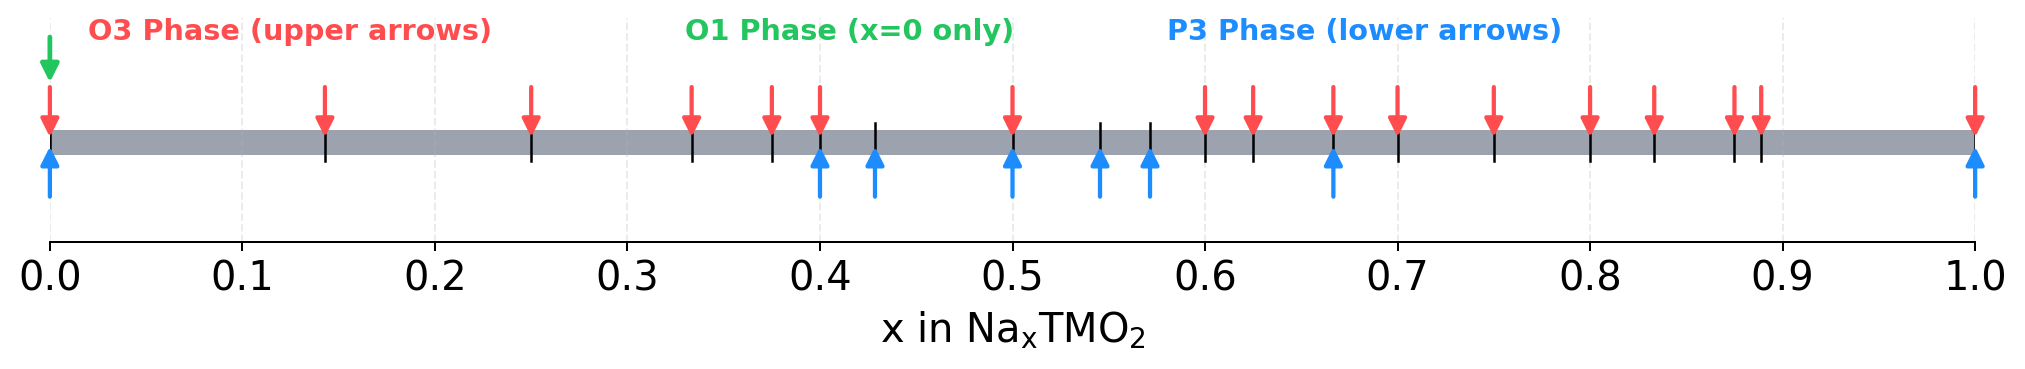

All x ticks: [0.0, 0.14285714285714285, 0.25, 0.3333333333333333, 0.375, 0.4, 0.42857142857142855, 0.5, 0.5454545454545454, 0.5714285714285714, 0.6, 0.625, 0.6666666666666666, 0.7, 0.75, 0.8, 0.8333333333333334, 0.875, 0.8888888888888888, 1.0]
O3 arrow x: [0.0, 0.14285714285714285, 0.25, 0.3333333333333333, 0.375, 0.4, 0.5, 0.6, 0.625, 0.6666666666666666, 0.7, 0.75, 0.8, 0.8333333333333334, 0.875, 0.8888888888888888, 1.0]
O1 arrow x: [0.0]
P3 arrow x: [0.0, 0.4, 0.42857142857142855, 0.5, 0.5454545454545454, 0.5714285714285714, 0.6666666666666666, 1.0]


In [36]:
# Re-done: horizontal gray bar + inward phase arrows (display only)
import matplotlib.pyplot as plt
import numpy as np

na_map = {
    "AJT_a": 1/7, "AJT_b": 1/4, "AJT_c": 1/4, "AJT_d": 1/3, "AJT_e": 1/3,
    "AJT_f": 2/5, "AJT_g": 1/2, "AJT_h": 3/5, "AJT_i": 5/8, "AJT_j": 5/8,
    "AJT_k": 2/3, "AJT_l": 2/3, "AJT_m": 2/3, "AJT_n": 3/4, "AJT_o": 3/4,
    "AJT_p": 5/6, "AJT_q": 7/8, "AJT_r": 8/9,
    "JLK_b": 3/8, "JLK_c": 7/10, "JLK_theta_4": 4/5, "JLK_theta_5": 5/6,
    "JLK_delta": 2/3, "JLK_eta": 4/7, "JLK_zeta": 1/2, "JLK_zeta2": 2/5,
    "JLK_zeta3": 3/7, "JLK_zeta6": 6/11,
    "CD_a": 1/2, "JMAS_a": 1/3, "JMAS_b": 2/5, "JMAS_e": 1, "XC_a": 1/3,
    "XC_b": 1/2, "JMAS_c": 1/2, "JMAS_d": 2/3, "XL_a": 5/8
}

# Required additional points
na_map_extra = {
    'O1_empty': 0.0,
    'O3_empty': 0.0,
    'O3_full': 1.0,
    'P3_empty': 0.0,
    'P3_full': 1.0,
}

# Same phase color scheme as voltage curves
O3_COLOR = '#ff4d4f'
P3_COLOR = '#1d8cff'
O1_COLOR = '#22c55e'
BAR_GRAY = '#9ca3af'

# Explicit P3 orderings from your note
p3_orderings = {
    'JLK_delta', 'JLK_eta', 'JLK_zeta', 'JLK_zeta2', 'JLK_zeta3', 'JLK_zeta6',
    'JMAS_c', 'JMAS_d'
}

all_map = dict(na_map)
all_map.update(na_map_extra)

# Assign O3/P3 class for base arrows
phase_by_key = {}
for k in all_map.keys():
    if k.startswith('P3_') or k in p3_orderings:
        phase_by_key[k] = 'P3'
    else:
        phase_by_key[k] = 'O3'

# Ticks for all data-point x values on [0, 1]
x_ticks = sorted(set(float(v) for v in all_map.values() if 0.0 <= float(v) <= 1.0))
if len(x_ticks) < 2:
    raise RuntimeError('Not enough unique x values to draw bar.')

# Unique x positions by phase (arrows)
x_o3 = sorted(set(float(v) for k, v in all_map.items() if phase_by_key[k] == 'O3'))
x_p3 = sorted(set(float(v) for k, v in all_map.items() if phase_by_key[k] == 'P3'))
# O1 only at x = 0.0 (requested)
x_o1 = [0.0]

fig, ax = plt.subplots(figsize=(11.5, 2.3), dpi=180)

# Gray bar from 0 to 1
y_bar = 0.50
ax.plot([0.0, 1.0], [y_bar, y_bar], color=BAR_GRAY, linewidth=10, solid_capstyle='round', zorder=1)

# Tick marks where data points exist
for x in x_ticks:
    ax.plot([x, x], [y_bar - 0.08, y_bar + 0.08], color='black', linewidth=1.0, zorder=3)

# O3 arrows above bar (pointing toward bar)
for x in x_o3:
    ax.annotate(
        '',
        xy=(x, y_bar + 0.02),
        xytext=(x, y_bar + 0.23),
        arrowprops=dict(arrowstyle='-|>', color=O3_COLOR, lw=1.7, shrinkA=0, shrinkB=0),
        zorder=4, alpha=0.2,
    )

# O1 arrows above O3 arrows (also pointing toward bar) -- only at x=0.0
for x in x_o1:
    ax.annotate(
        '',
        xy=(x, y_bar + 0.25),
        xytext=(x, y_bar + 0.44),
        arrowprops=dict(arrowstyle='-|>', color=O1_COLOR, lw=1.9, shrinkA=0, shrinkB=0),
        zorder=5, alpha=0.2,
    )

# P3 arrows below bar (pointing toward bar)
for x in x_p3:
    ax.annotate(
        '',
        xy=(x, y_bar - 0.02),
        xytext=(x, y_bar - 0.23),
        arrowprops=dict(arrowstyle='-|>', color=P3_COLOR, lw=1.7, shrinkA=0, shrinkB=0),
        zorder=4, alpha=0.2,
    )

# Professional phase labels
ax.text(0.02, 0.94, 'O3 Phase (upper arrows)', color=O3_COLOR, 
        transform=ax.transAxes, fontsize=11.5, fontweight='semibold', va='center', ha='left')
ax.text(0.33, 0.94, 'O1 Phase (x=0 only)', color=O1_COLOR,
        transform=ax.transAxes, fontsize=11.5, fontweight='semibold', va='center', ha='left')
ax.text(0.58, 0.94, 'P3 Phase (lower arrows)', color=P3_COLOR,
        transform=ax.transAxes, fontsize=11.5, fontweight='semibold', va='center', ha='left')

# Axis style
ax.set_xlim(0, 1)
ax.set_ylim(0.08, 1.02)
ax.set_yticks([])
ax.set_xlabel('x in Na$_{\mathrm{x}}$TMO$_2$', fontsize=16)
ax.set_xticks(np.linspace(0, 1, 11))
ax.grid(axis='x', linestyle='--', alpha=0.25)
for spine in ['left', 'right', 'top']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

print('All x ticks:', x_ticks)
print('O3 arrow x:', x_o3)
print('O1 arrow x:', x_o1)
print('P3 arrow x:', x_p3)


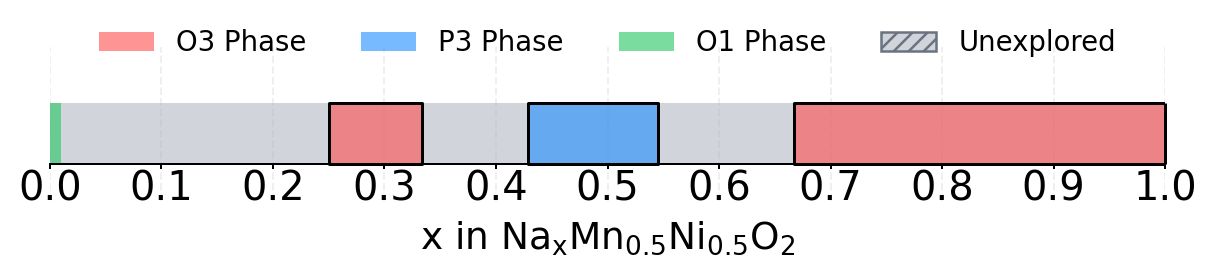

Current phase_intervals:
  O3: [(0.667, 1.0), (0.25, 0.3333333333333333)]
  P3: [(0.429, 0.5454545454545454)]
  O1: [(0, 0.01)]
  unknown: []


In [69]:
# Clean re-do: dictionary-driven phase bar (display only)
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

# Edit ONLY this dictionary to tweak regions.
# Format: {"PHASE": [(x_start, x_end), ...]}
# Use 'unknown' (or 'unknow') for hatched unexplored ranges on gray bar.
phase_intervals = {
    'O3': [(0.667, 1.00), (1/4, 1/3)],
    'P3': [(0.429, 6/11)],
    'O1': [(0, 0.01)],
    'unknown': [],
}

# Exactly the same phase colors used in voltage curves
phase_colors = {
    'O3': '#ff4d4f',
    'P3': '#1d8cff',
    'O1': '#22c55e',
}
bar_gray = '#d1d5db'

fig, ax = plt.subplots(figsize=(7, 1.8), dpi=180)

y0, h = 0.40, 0.20

# Base undesignated region (gray)
ax.broken_barh([(0.0, 1.0)], (y0, h), facecolors=bar_gray, edgecolors='none', alpha=1.0, zorder=1)

# Overlay designated phase intervals (same alpha style as voltage curve)
for phase, ranges in phase_intervals.items():
    if phase not in phase_colors:
        continue
    for a, b in ranges:
        left = max(0.0, min(float(a), float(b)))
        right = min(1.0, max(float(a), float(b)))
        if right <= left:
            continue
        ax.broken_barh(
            [(left, right - left)],
            (y0, h),
            facecolors=phase_colors[phase],
            edgecolors='none',
            alpha=0.60,
            zorder=2,
        )
        if phase in ('O3', 'P3'):
            ax.broken_barh(
                [(left, right - left)],
                (y0, h),
                facecolors='none',
                edgecolors='black',
                linewidth=1.2,
                zorder=3,
            )

# Hatched unexplored intervals on gray bar
unknown_ranges = list(phase_intervals.get('unknown', [])) + list(phase_intervals.get('unknow', []))
for a, b in unknown_ranges:
    left = max(0.0, min(float(a), float(b)))
    right = min(1.0, max(float(a), float(b)))
    if right <= left:
        continue
    ax.add_patch(
        Rectangle(
            (left, y0),
            right - left,
            h,
            facecolor='none',
            edgecolor='#6b7280',
            hatch='////',
            linewidth=0.8,
            zorder=2.6,
        )
    )

# Ensure right edge at x=1.0 is outlined
ax.vlines(1.0, y0, y0 + h, colors='black', linewidth=1.2, zorder=4, clip_on=False)

# Simple phase legend
handles = [
    Patch(facecolor=phase_colors['O3'], edgecolor='none', label='O3 Phase', alpha=0.60),
    Patch(facecolor=phase_colors['P3'], edgecolor='none', label='P3 Phase', alpha=0.60),
    Patch(facecolor=phase_colors['O1'], edgecolor='none', label='O1 Phase', alpha=0.60),
    Patch(facecolor=bar_gray, edgecolor='#6b7280', hatch='////', label='Unexplored'),
]
ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.28), ncol=4, frameon=False, fontsize=11)

ax.set_xlim(0, 1)
ax.set_ylim(0.28, 0.78)
ax.set_yticks([])
ax.set_xlabel('x in Na$_{\mathrm{x}}$Mn$_{0.5}$Ni$_{0.5}$O$_2$', fontsize=15)
ax.set_xticks([i / 10 for i in range(11)])
ax.grid(axis='x', linestyle='--', alpha=0.20)

# Move x-axis ticks close to the bar
for spine in ['left', 'right', 'top']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_position(('data', y0))
ax.tick_params(axis='x', which='major', pad=0, length=2)

plt.tight_layout()
plt.show()

print('Current phase_intervals:')
for ph, segs in phase_intervals.items():
    print(f'  {ph}: {segs}')
